# Classification du positionnement des communications de la BCE

In [1]:
!pip install torch

## Démonstration pédagogique : principes des RNN et LSTM

In [2]:
# Reproductibilité des expériences
# À exécuter avant toute initialisation de modèle et tout entraînement.
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed fixée à {SEED}")

Seed fixée à 42


In [3]:
import torch
import torch.nn as nn

# On crée un RNN simple
rnn=nn.RNN(input_size=4, hidden_size=3, batch_first=True)
print(rnn)


RNN(4, 3, batch_first=True)


In [4]:
# Une phrase fictive : 2 mots, chaque mot = 4 chiffres
phrase = torch.tensor([[[1.0, 0.5, 0.2, 0.8],   # mot 1
                         [0.3, 0.9, 0.1, 0.4]]])  # mot 2
print("Forme de la phrase :", phrase.shape)

Forme de la phrase : torch.Size([1, 2, 4])


In [5]:
# Le RNN lit la phrase
output, hidden = rnn(phrase)

print("Output :", output)
print("Hidden :", hidden)

Output : tensor([[[ 0.5041, -0.3398,  0.6069],
         [ 0.5344, -0.4356, -0.2566]]], grad_fn=<TransposeBackward1>)
Hidden : tensor([[[ 0.5344, -0.4356, -0.2566]]], grad_fn=<StackBackward0>)


In [6]:
lstm = nn.LSTM(input_size=4, hidden_size=3, batch_first=True)

output, (hidden, cell) = lstm(phrase)

print("Output :", output.shape)
print("Hidden :", hidden.shape)
print("Cell   :", cell.shape)

Output : torch.Size([1, 2, 3])
Hidden : torch.Size([1, 1, 3])
Cell   : torch.Size([1, 1, 3])


## 1. Données et exploration

In [7]:
!pip install datasets

In [8]:
#On importe la fonction load_dataset depuis la librairie HuggingFace datasets.
from datasets import load_dataset

dataset = load_dataset("gtfintechlab/european_central_bank", "5768")

print(dataset)

README.md:   0%|          | 0.00/4.28k [00:00<?, ?B/s]

5768/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 73.6kB            

5768/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

5768/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.4kB            

5768/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

5768/val-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.3kB            

5768/val-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/700 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/150 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/150 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentences', 'stance_label', 'time_label', 'certain_label', 'year', '__index_level_0__'],
        num_rows: 700
    })
    test: Dataset({
        features: ['sentences', 'stance_label', 'time_label', 'certain_label', 'year', '__index_level_0__'],
        num_rows: 150
    })
    val: Dataset({
        features: ['sentences', 'stance_label', 'time_label', 'certain_label', 'year', '__index_level_0__'],
        num_rows: 150
    })
})


In [9]:
# Convertit les exemples en DataFrame.
import pandas as pd

df_train = dataset["train"].to_pandas()

df_train.head()

,sentences,stance_label,time_label,certain_label,year,__index_level_0__
0,"moreover, although there was tentative evidenc...",neutral,forward looking,certain,2023,705
1,"summing up, mr praet noted that the euro area ...",dovish,forward looking,certain,2015,921
2,"looking ahead, members voiced some nuances rel...",neutral,forward looking,uncertain,2022,158
3,"however, it was also argued that a more modera...",neutral,not forward looking,certain,2021,654
4,the question was posed as to whether the stron...,neutral,not forward looking,certain,2015,822


In [10]:
# Affiche le nombre d’exemples et les colonnes disponibles.
print("Nombre de phrases :", len(df_train))
print("Colonnes :", df_train.columns.tolist())

Nombre de phrases : 700
Colonnes : ['sentences', 'stance_label', 'time_label', 'certain_label', 'year', '__index_level_0__']


In [11]:
#voir combien de fois chaque label apparaît.
print(df_train["stance_label"].value_counts())

stance_label
neutral       289
dovish        237
hawkish       157
irrelevant     17
Name: count, dtype: int64


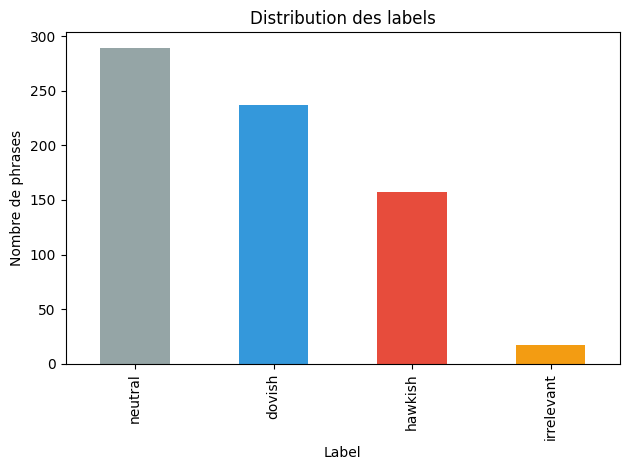

In [12]:
# Visualise la répartition des classes.
import matplotlib.pyplot as plt

df_train["stance_label"].value_counts().plot(kind="bar", color=["#95a5a6", "#3498db", "#e74c3c", "#f39c12"])
plt.title("Distribution des labels")
plt.xlabel("Label")
plt.ylabel("Nombre de phrases")
plt.tight_layout()
plt.show()

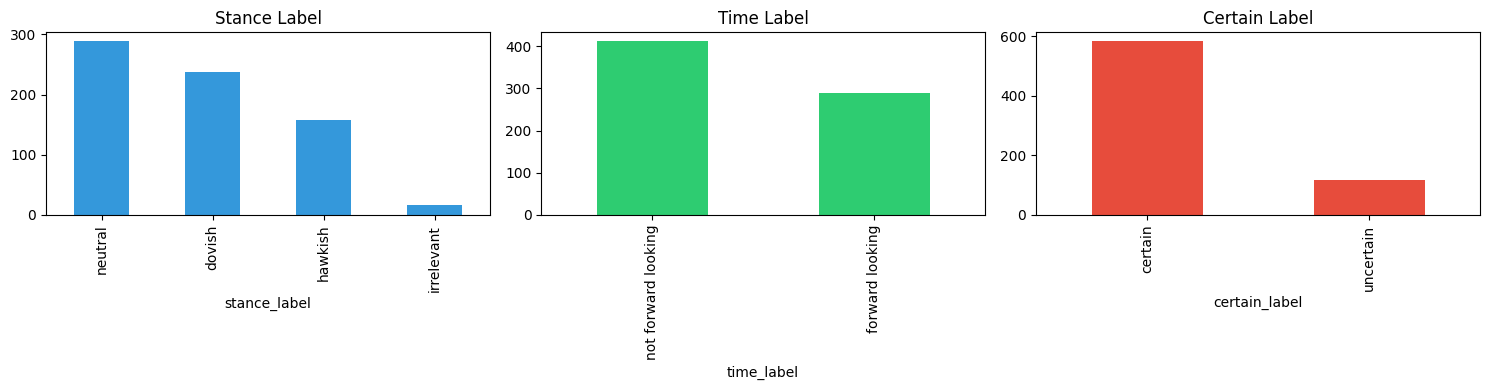

In [13]:
# Visualisation de la distribution des 3 labels
# Pour vérifier si le dataset est équilibré ou non
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Distribution du stance label (hawkish, dovish, neutral, irrelevant)
df_train["stance_label"].value_counts().plot(kind="bar", ax=axes[0], color="#3498db")
axes[0].set_title("Stance Label")

# Distribution du time label (forward looking, not forward looking)
df_train["time_label"].value_counts().plot(kind="bar", ax=axes[1], color="#2ecc71")
axes[1].set_title("Time Label")

# Distribution du certain label (certain, uncertain)
df_train["certain_label"].value_counts().plot(kind="bar", ax=axes[2], color="#e74c3c")
axes[2].set_title("Certain Label")

plt.tight_layout()
plt.show()

count    700.000000
mean      27.661429
std       11.625090
min        4.000000
25%       19.000000
50%       26.000000
75%       34.000000
max       78.000000
Name: length, dtype: float64


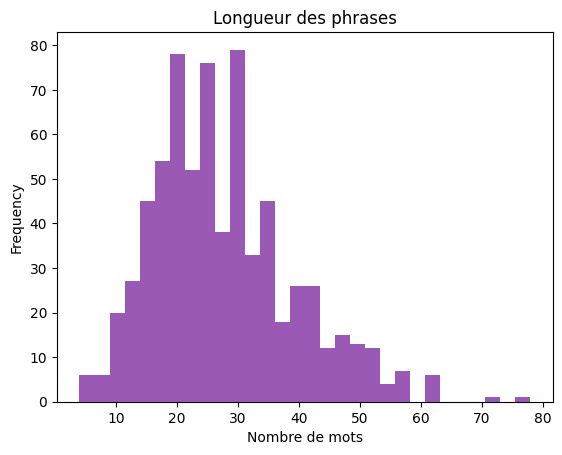

In [14]:
# Calcul du nombre de mots dans chaque phrase
# Utile pour choisir la taille maximale des séquences pour le LSTM
df_train["length"] = df_train["sentences"].apply(lambda x: len(x.split()))

# Statistiques de base : moyenne, min, max, etc.
print(df_train["length"].describe())

# Histogramme de la distribution des longueurs
df_train["length"].plot(kind="hist", bins=30, color="#9b59b6")
plt.title("Longueur des phrases")
plt.xlabel("Nombre de mots")
plt.show()

## 2. Prétraitement des textes et des étiquettes

In [15]:
# On récupère toutes les phrases du dataset
toutes_les_phrases = df_train["sentences"].tolist()

# On affiche les 3 premières phrases pour vérifier
for phrase in toutes_les_phrases[:3]:
    print(phrase)
    print("---")

moreover, although there was tentative evidence suggesting that wage growth was close to a peak, further evidence was required to be sure it was turning.
---
summing up, mr praet noted that the euro area economic recovery was expected to continue at a somewhat slower pace than previously anticipated, largely reflecting the slowdown in emerging market economies.
---
looking ahead, members voiced some nuances related to the appropriate pace of the gradual normalisation.
---


In [16]:
import re

# Fonction pour nettoyer une phrase
def nettoyer(phrase):
    # Met tout en minuscule
    phrase = phrase.lower()
    # Supprime la ponctuation
    phrase = re.sub(r'[^\w\s]', '', phrase)
    return phrase

# Test sur une phrase
exemple = "labour. effects; expenditure,"
print("Avant :", exemple)
print("Après :", nettoyer(exemple))

Avant : labour. effects; expenditure,
Après : labour effects expenditure


In [17]:
# On nettoie toutes les phrases et on reconstruit le vocabulaire
vocabulaire = set()
for phrase in toutes_les_phrases:
    phrase_nettoyee = nettoyer(phrase)
    mots = phrase_nettoyee.split()
    for mot in mots:
        vocabulaire.add(mot)

print("Nombre de mots uniques après nettoyage :", len(vocabulaire))

Nombre de mots uniques après nettoyage : 2341


In [18]:
# On convertit le vocabulaire en dictionnaire mot → numéro
# On commence à 1 (on réserve 0 pour le padding)
mot2idx = {"<PAD>": 0, "<UNK>": 1}

# Un ordre alphabétique rend les indices reproductibles.
for idx, mot in enumerate(sorted(vocabulaire), start=2):
    mot2idx[mot] = idx

print("Taille du vocabulaire :", len(mot2idx))
print("\nExemples :")
print("'rates' →", mot2idx.get("rates", 1))
print("'inflation' →", mot2idx.get("inflation", 1))
print("'<PAD>' →", mot2idx["<PAD>"])
print("'<UNK>' →", mot2idx["<UNK>"])

Taille du vocabulaire : 2343

Exemples :
'rates' → 1671
'inflation' → 1097
'<PAD>' → 0
'<UNK>' → 1


In [19]:
# Convertit une phrase en indices, puis applique troncature et padding.
def phrase_vers_nombres(phrase, max_length=50):
    phrase = nettoyer(phrase)
    mots = phrase.split()
    nombres = [mot2idx.get(mot, 1) for mot in mots]
    nombres = nombres[:max_length]
    nombres = nombres + [0] * (max_length - len(nombres))
    return nombres

# Exemple : un mot inconnu est converti en indice <UNK>.
exemple = "the rates xyzabc rising"
print("Phrase :", exemple)
print("Indices :", phrase_vers_nombres(exemple))

Phrase : the rates xyzabc rising
Indices : [2114, 1671, 1, 1827, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [20]:
# "xyzabc" est un mot qui n'existe pas dans le vocabulaire
exemple = "the rates xyzabc rising"
print("Phrase :", exemple)
print("Nombres :", phrase_vers_nombres(exemple))

Phrase : the rates xyzabc rising
Nombres : [2114, 1671, 1, 1827, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [21]:
# Encode les étiquettes de classe.
label2idx = {"hawkish": 0, "dovish": 1, "neutral": 2, "irrelevant": 3}

X_train = [phrase_vers_nombres(p) for p in df_train["sentences"]]
y_train = [label2idx[l] for l in df_train["stance_label"]]

print("Exemple phrase :", X_train[0])
print("Exemple label :", y_train[0])

Exemple phrase : [1318, 180, 2120, 2281, 2104, 781, 2055, 2113, 2273, 980, 2281, 394, 2147, 90, 1476, 943, 781, 2281, 1779, 2147, 279, 2064, 1135, 2281, 2178, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Exemple label : 2


In [22]:
X_train = torch.tensor(X_train)
y_train = torch.tensor(y_train)

print("Shape X_train :", X_train.shape)
print("Shape y_train :", y_train.shape)

Shape X_train : torch.Size([700, 50])
Shape y_train : torch.Size([700])


## 3. Modèles et premières expériences d’entraînement

## Démonstration guidée : architecture LSTM

Cette première implémentation illustre les principales étapes du traitement d’une phrase. Elle précède les expérimentations comparatives menées sur le jeu de données.

Phrase encodée en indices → plongement (embedding) → LSTM → couche linéaire → classe prédite.

In [23]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_classes):
        super(LSTMClassifier, self).__init__()

        # Couche 1 : Embedding
        # Convertit chaque numéro en vecteur
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Couche 2 : LSTM
        # Lit la séquence et produit une mémoire
        self.lstm = nn.LSTM(embed_dim, hidden_size, batch_first=True)

        # Couche 3 : Linear
        # Prédit le label final
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Étape 1 : Embedding
        embedded = self.embedding(x)

        # Étape 2 : LSTM
        output, (hidden, cell) = self.lstm(embedded)

        # Étape 3 : Linear
        # On prend juste le dernier hidden state
        out = self.fc(hidden[-1])
        return out

In [24]:
# On définit les paramètres du modèle
VOCAB_SIZE  = len(mot2idx)   # 2343 mots
EMBED_DIM   = 64             # chaque mot = vecteur de 64 chiffres
HIDDEN_SIZE = 128            # taille de la mémoire du LSTM
NUM_CLASSES = 4              # hawkish, dovish, neutral, irrelevant

# On crée le modèle
model = LSTMClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_SIZE, NUM_CLASSES)

print(model)
print(f"\nNombre de paramètres : {sum(p.numel() for p in model.parameters()):,}")

LSTMClassifier(
  (embedding): Embedding(2343, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=4, bias=True)
)

Nombre de paramètres : 249,796


In [25]:
# Loss function : mesure l'erreur entre prédiction et vrai label
criterion = nn.CrossEntropyLoss()

# Optimizer : corrige le modèle après chaque erreur
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("criterion :", criterion)
print("optimizer :", optimizer)

criterion : CrossEntropyLoss()
optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [26]:
# Nombre de passages sur le jeu d’entraînement.
NB_EPOCHS = 10

for epoch in range(NB_EPOCHS):

    # Mode entraînement
    model.train()

    # Forward pass : le modèle fait ses prédictions
    predictions = model(X_train)

    # Calcul de l'erreur
    loss = criterion(predictions, y_train)

    # On remet les gradients à zéro
    optimizer.zero_grad()

    # Backward pass : on calcule les corrections
    loss.backward()

    # On applique les corrections
    optimizer.step()

    print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss: {loss.item():.4f}")

Epoch 1/10 - Loss: 1.3958
Epoch 2/10 - Loss: 1.3881
Epoch 3/10 - Loss: 1.3804
Epoch 4/10 - Loss: 1.3725
Epoch 5/10 - Loss: 1.3643
Epoch 6/10 - Loss: 1.3555
Epoch 7/10 - Loss: 1.3460
Epoch 8/10 - Loss: 1.3354
Epoch 9/10 - Loss: 1.3233
Epoch 10/10 - Loss: 1.3092


In [27]:
NB_EPOCHS = 50

for epoch in range(NB_EPOCHS):
    model.train()
    predictions = model(X_train)
    loss = criterion(predictions, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Affiche la perte toutes les dix époques.
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss: {loss.item():.4f}")

Epoch 10/50 - Loss: 1.1486
Epoch 20/50 - Loss: 1.1418
Epoch 30/50 - Loss: 1.1338
Epoch 40/50 - Loss: 1.1239
Epoch 50/50 - Loss: 1.1117


In [28]:
# Mode évaluation
model.eval()

# On désactive le calcul des gradients
with torch.no_grad():
    predictions = model(X_train)

    # On prend le label avec la plus grande probabilité
    predicted_labels = torch.argmax(predictions, dim=1)

    # On compare avec les vrais labels
    correct = (predicted_labels == y_train).sum().item()
    accuracy = correct / len(y_train) * 100

    print(f"Accuracy : {accuracy:.2f}%")
    print(f"Bonnes prédictions : {correct}/{len(y_train)}")

Accuracy : 45.29%
Bonnes prédictions : 317/700


In [29]:
from torch.utils.data import Dataset, DataLoader

# Classe qui organise nos données
class ECBDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    # Nombre total d'exemples
    def __len__(self):
        return len(self.X)

    # Retourne un exemple par son index
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# On crée le dataset
train_dataset = ECBDataset(X_train, y_train)

# On crée le DataLoader avec des batches de 32
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=train_generator
)

print("Nombre de batches :", len(train_loader))
print("Taille d'un batch : 32 phrases")

Nombre de batches : 22
Taille d'un batch : 32 phrases


In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

NB_EPOCHS = 10

for epoch in range(NB_EPOCHS):
    model.train()
    total_loss = 0

    # On parcourt les batches un par un
    for X_batch, y_batch in train_loader:

        # Prédictions sur le batch
        predictions = model(X_batch)

        # Calcul de l'erreur
        loss = criterion(predictions, y_batch)

        # Corrections
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Loss moyenne sur tous les batches
    loss_moyenne = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss: {loss_moyenne:.4f}")

Epoch 1/10 - Loss: 1.1215
Epoch 2/10 - Loss: 1.1246
Epoch 3/10 - Loss: 1.1077
Epoch 4/10 - Loss: 1.1179
Epoch 5/10 - Loss: 1.0842
Epoch 6/10 - Loss: 1.0763
Epoch 7/10 - Loss: 1.0614
Epoch 8/10 - Loss: 1.0667
Epoch 9/10 - Loss: 1.0235
Epoch 10/10 - Loss: 0.9557


In [31]:
NB_EPOCHS = 20

for epoch in range(NB_EPOCHS):
    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    loss_moyenne = total_loss / len(train_loader)

    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss: {loss_moyenne:.4f}")

Epoch 5/20 - Loss: 0.6797
Epoch 10/20 - Loss: 0.5544
Epoch 15/20 - Loss: 0.3209
Epoch 20/20 - Loss: 0.2490


### Classificateur RNN et entraînement initial

In [32]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_classes):
        super(RNNClassifier, self).__init__()

        # Couche 1 : Embedding
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Couche 2 : RNN (au lieu de LSTM)
        self.rnn = nn.RNN(embed_dim, hidden_size, batch_first=True)

        # Couche 3 : Linear
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.rnn(embedded)
        out = self.fc(hidden[-1])
        return out

In [33]:
# On crée le modèle RNN avec les mêmes paramètres que le LSTM
model_rnn = RNNClassifier(
    vocab_size=len(mot2idx),
    embed_dim=64,
    hidden_size=128,
    num_classes=4
)

print(model_rnn)

RNNClassifier(
  (embedding): Embedding(2343, 64, padding_idx=0)
  (rnn): RNN(64, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=4, bias=True)
)


In [34]:
# ─────────────────────────────────────────────
# Étape 1 : Définir la fonction de perte (loss)
# CrossEntropyLoss mesure l'erreur entre la prédiction et le vrai label
# Plus la loss est grande → plus le modèle se trompe
# ─────────────────────────────────────────────
criterion_rnn = nn.CrossEntropyLoss()

# ─────────────────────────────────────────────
# Étape 2 : Définir l'optimizer
# Adam va corriger le modèle après chaque erreur
# lr=0.001 → vitesse d'apprentissage (ni trop vite, ni trop lentement)
# ─────────────────────────────────────────────
optimizer_rnn = torch.optim.Adam(model_rnn.parameters(), lr=0.001)

# ─────────────────────────────────────────────
# Étape 3 : Définir le nombre d'epochs
# Une epoch = le modèle parcourt toutes les 700 phrases une fois
# ─────────────────────────────────────────────
NB_EPOCHS = 30

# ─────────────────────────────────────────────
# Étape 4 : La boucle d'entraînement
# On répète NB_EPOCHS fois le même cycle
# ─────────────────────────────────────────────
for epoch in range(NB_EPOCHS):

    # On met le modèle en mode entraînement
    # Il est prêt à apprendre et corriger ses erreurs
    model_rnn.train()

    # On initialise la loss totale à 0 pour cette epoch
    total_loss = 0

    # On parcourt les 22 batches un par un
    # Chaque batch contient 32 phrases
    for X_batch, y_batch in train_loader:

        # Forward pass : le modèle lit les 32 phrases
        # et prédit un label pour chacune
        predictions = model_rnn(X_batch)

        # On calcule l'erreur entre prédiction et vrai label
        loss = criterion_rnn(predictions, y_batch)

        # On remet les corrections à zéro
        # (obligatoire avant chaque backward pass)
        optimizer_rnn.zero_grad()

        # Backward pass : PyTorch calcule les corrections
        # pour réduire l'erreur
        loss.backward()

        # On applique les corrections sur les 249,796 paramètres
        optimizer_rnn.step()

        # On ajoute la loss de ce batch à la loss totale
        total_loss += loss.item()

    # On calcule la loss moyenne sur les 22 batches
    loss_moyenne = total_loss / len(train_loader)

    # On affiche la loss toutes les 5 epochs
    # pour surveiller que le modèle apprend bien
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss: {loss_moyenne:.4f}")

Epoch 5/30 - Loss: 1.1208
Epoch 10/30 - Loss: 1.0825
Epoch 15/30 - Loss: 1.0551
Epoch 20/30 - Loss: 1.0017
Epoch 25/30 - Loss: 0.9900
Epoch 30/30 - Loss: 0.8636


In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# On met le modèle en mode évaluation
model_rnn.eval()

with torch.no_grad():
    # Le modèle prédit sur toutes les phrases
    predictions = model_rnn(X_train)

    # On prend le label avec le score le plus élevé
    predicted_labels = torch.argmax(predictions, dim=1)

    # On convertit en numpy pour sklearn
    y_true = y_train.numpy()
    y_pred = predicted_labels.numpy()

# Calcul des métriques
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall    = recall_score(y_true, y_pred, average='weighted')
f1        = f1_score(y_true, y_pred, average='weighted')

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")

Accuracy  : 63.29%
Precision : 66.00%
Recall    : 63.29%
F1 Score  : 61.58%


### Préparation des jeux de validation et de test

In [36]:
# Préparer les données de validation et de test
df_val = dataset["val"].to_pandas()
df_test = dataset["test"].to_pandas()

# Validation
X_val = [phrase_vers_nombres(p) for p in df_val["sentences"]]
y_val = [label2idx[l] for l in df_val["stance_label"]]

# Test
X_test = [phrase_vers_nombres(p) for p in df_test["sentences"]]
y_test = [label2idx[l] for l in df_test["stance_label"]]

# Convertir en tenseurs
X_val = torch.tensor(X_val)
y_val = torch.tensor(y_val)
X_test = torch.tensor(X_test)
y_test = torch.tensor(y_test)

print("Shape X_val   :", X_val.shape)
print("Shape y_val   :", y_val.shape)
print("Shape X_test  :", X_test.shape)
print("Shape y_test  :", y_test.shape)


Shape X_val   : torch.Size([150, 50])
Shape y_val   : torch.Size([150])
Shape X_test  : torch.Size([150, 50])
Shape y_test  : torch.Size([150])


## Diagnostic du surapprentissage

On compare la perte d’entraînement à celle de validation. Une perte d’entraînement qui diminue alors que la perte de validation cesse de s’améliorer peut signaler un surapprentissage.

Le jeu de test reste réservé à l’évaluation finale.

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np
# Mode évaluation
model_rnn.eval()

with torch.no_grad():
    # Prédictions sur le test
    predictions_test = model_rnn(X_test)
    predicted_labels = torch.argmax(predictions_test, dim=1)

    # Probabilités pour AUC
    probs = torch.softmax(predictions_test, dim=1).numpy()

    y_true = y_test.numpy()
    y_pred = predicted_labels.numpy()

# Calcul des métriques
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall    = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1        = f1_score(y_true, y_pred, average='weighted', zero_division=0)

# AUC
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
auc = roc_auc_score(y_true_bin, probs, average='weighted', multi_class='ovr')

print("=== Résultats RNN sur le Test Set ===")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")
print(f"AUC       : {auc*100:.2f}%")

=== Résultats RNN sur le Test Set ===
Accuracy  : 35.33%
Precision : 34.76%
Recall    : 35.33%
F1 Score  : 33.61%
AUC       : 52.93%


## 4. DistilBERT : préparation et entraînement

In [38]:
!pip install transformers

In [39]:
from transformers import AutoTokenizer

# Chargement du tokenizer DistilBERT
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# Test sur une vraie phrase du dataset
exemple = "the rates are rising due to inflation"
tokens = tokenizer(exemple, return_tensors="pt",
                   truncation=True, max_length=128, padding=True)

print("Phrase :", exemple)
print("Input IDs :", tokens["input_ids"])
print("Tokens :", tokenizer.convert_ids_to_tokens(tokens["input_ids"][0]))


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Phrase : the rates are rising due to inflation
Input IDs : tensor([[  101,  1996,  6165,  2024,  4803,  2349,  2000, 14200,   102]])
Tokens : ['[CLS]', 'the', 'rates', 'are', 'rising', 'due', 'to', 'inflation', '[SEP]']


In [40]:
# Fonction de tokenisation des phrases
def tokeniser_dataset(df, max_length=128):
    return tokenizer(
        df["sentences"].tolist(),
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )

In [41]:
# Préparer les données pour DistilBERT
train_encodings = tokeniser_dataset(df_train)
val_encodings   = tokeniser_dataset(df_val)
test_encodings  = tokeniser_dataset(df_test)

y_train_bert = torch.tensor([label2idx[l] for l in df_train["stance_label"]])
y_val_bert   = torch.tensor([label2idx[l] for l in df_val["stance_label"]])
y_test_bert  = torch.tensor([label2idx[l] for l in df_test["stance_label"]])

print("Train encodings shape :", train_encodings["input_ids"].shape)
print("Val encodings shape   :", val_encodings["input_ids"].shape)
print("Test encodings shape  :", test_encodings["input_ids"].shape)


Train encodings shape : torch.Size([700, 94])
Val encodings shape   : torch.Size([150, 79])
Test encodings shape  : torch.Size([150, 80])


In [42]:
import torch.nn as nn
from transformers import AutoModel

# ─────────────────────────────────────────────────────────
# Classe DistilBERTClassifier
#
# Au lieu d'utiliser AutoModelForSequenceClassification
# (qui fait tout automatiquement), on construit notre propre
# classificateur — comme pour LSTM et RNN.
# ─────────────────────────────────────────────────────────

class DistilBERTClassifier(nn.Module):
    def __init__(self, num_classes):
        super(DistilBERTClassifier, self).__init__()

        # On charge DistilBERT pré-entraîné (sans la couche de classification)
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")

        # On freeze toutes les couches de DistilBERT
        # → elles ne vont PAS apprendre, on garde ce qu'il sait déjà
        for param in self.bert.parameters():
            param.requires_grad = False

        # Notre nouvelle couche de classification (entraînable)
        # 768 = taille de sortie de DistilBERT
        self.classifier = nn.Linear(768, num_classes)

    def forward(self, input_ids, attention_mask):
        # DistilBERT traite la phrase
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)

        # On prend la représentation du token [CLS]
        # (premier token, résume toute la phrase)
        cls_output = outputs.last_hidden_state[:, 0, :]

        # Notre couche de classification prédit le label
        logits = self.classifier(cls_output)
        return logits


# On crée le modèle
model_bert = DistilBERTClassifier(num_classes=4)

print(model_bert)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERTClassifier(
  (bert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)

In [43]:
# Compter les paramètres entraînables vs total
total_params = sum(p.numel() for p in model_bert.parameters())
trainable_params = sum(p.numel() for p in model_bert.parameters() if p.requires_grad)

print(f"Total paramètres        : {total_params:,}")
print(f"Paramètres entraînables : {trainable_params:,}")
print(f"Paramètres freezés      : {total_params - trainable_params:,}")

Total paramètres        : 66,365,956
Paramètres entraînables : 3,076
Paramètres freezés      : 66,362,880


In [44]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

# On envoie le modèle sur le GPU
model_bert.to(device)

Device utilisé : cuda


DistilBERTClassifier(
  (bert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)

In [45]:
# Envoyer les données sur le même device que le modèle
train_encodings_ids  = train_encodings["input_ids"].to(device)
train_encodings_mask = train_encodings["attention_mask"].to(device)
y_train_bert = y_train_bert.to(device)

val_encodings_ids  = val_encodings["input_ids"].to(device)
val_encodings_mask = val_encodings["attention_mask"].to(device)
y_val_bert = y_val_bert.to(device)

test_encodings_ids  = test_encodings["input_ids"].to(device)
test_encodings_mask = test_encodings["attention_mask"].to(device)
y_test_bert = y_test_bert.to(device)

print("Données train, validation et test envoyées sur le GPU.")


Données train, validation et test envoyées sur le GPU.


In [46]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset_bert = TensorDataset(
    train_encodings_ids,
    train_encodings_mask,
    y_train_bert
)

val_dataset_bert = TensorDataset(
    val_encodings_ids,
    val_encodings_mask,
    y_val_bert
)

test_dataset_bert = TensorDataset(
    test_encodings_ids,
    test_encodings_mask,
    y_test_bert
)

bert_train_generator = torch.Generator().manual_seed(SEED)
train_loader_bert = DataLoader(
    train_dataset_bert,
    batch_size=16,
    shuffle=True,
    generator=bert_train_generator
)
val_loader_bert   = DataLoader(val_dataset_bert, batch_size=16, shuffle=False)
test_loader_bert  = DataLoader(test_dataset_bert, batch_size=16, shuffle=False)

print("Batches train :", len(train_loader_bert))
print("Batches val   :", len(val_loader_bert))
print("Batches test  :", len(test_loader_bert))


Batches train : 44
Batches val   : 10
Batches test  : 10


In [47]:
import torch.nn as nn
from torch.optim import AdamW
import copy

criterion_bert = nn.CrossEntropyLoss()

# Seule la couche de classification est entraînée.
optimizer_bert = AdamW(
    filter(lambda p: p.requires_grad, model_bert.parameters()),
    lr=1e-3
)

train_losses_bert = []
val_losses_bert = []

NB_EPOCHS = 100
patience = 10
best_val_loss = float("inf")
epochs_no_improve = 0
best_epoch_bert = 0
best_model_state_bert = None

for epoch in range(NB_EPOCHS):

    # -------- Entraînement --------
    model_bert.train()
    total_loss_train = 0

    for batch in train_loader_bert:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)

        logits = model_bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion_bert(logits, labels)

        optimizer_bert.zero_grad()
        loss.backward()
        optimizer_bert.step()

        total_loss_train += loss.item()

    loss_train = total_loss_train / len(train_loader_bert)
    train_losses_bert.append(loss_train)

    # -------- Validation --------
    model_bert.eval()
    total_loss_val = 0

    with torch.no_grad():
        for batch in val_loader_bert:
            input_ids = batch[0].to(device)
            attention_mask = batch[1].to(device)
            labels = batch[2].to(device)

            logits = model_bert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion_bert(logits, labels)
            total_loss_val += loss.item()

    loss_val = total_loss_val / len(val_loader_bert)
    val_losses_bert.append(loss_val)

    # -------- Early Stopping sur la validation --------
    if loss_val < best_val_loss:
        best_val_loss = loss_val
        best_epoch_bert = epoch + 1
        epochs_no_improve = 0
        best_model_state_bert = copy.deepcopy(model_bert.state_dict())
    else:
        epochs_no_improve += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{NB_EPOCHS} - "
            f"Loss Train: {loss_train:.4f} - "
            f"Loss Val: {loss_val:.4f}"
        )

    if epochs_no_improve >= patience:
        print(f"\nEarly Stopping à l'epoch {epoch+1}.")
        print(
            f"Meilleur modèle : epoch {best_epoch_bert} "
            f"(Loss Val = {best_val_loss:.4f})"
        )
        break

# Restaurer le meilleur modèle sélectionné sur la validation
model_bert.load_state_dict(best_model_state_bert)
print(f"\nMeilleur epoch DistilBERT : {best_epoch_bert}")


Epoch 10/100 - Loss Train: 0.9472 - Loss Val: 1.0106
Epoch 20/100 - Loss Train: 0.8793 - Loss Val: 0.9472
Epoch 30/100 - Loss Train: 0.8314 - Loss Val: 0.9549

Early Stopping à l'epoch 31.
Meilleur modèle : epoch 21 (Loss Val = 0.9394)

Meilleur epoch DistilBERT : 21


### Évaluation de DistilBERT

In [48]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np

# Évaluation finale : le test set est utilisé uniquement ici.
model_bert.eval()

all_preds_bert = []
all_labels_bert = []
all_probs_bert = []

with torch.no_grad():
    for batch in test_loader_bert:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)

        logits = model_bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_preds_bert.extend(preds.cpu().numpy())
        all_labels_bert.extend(labels.cpu().numpy())
        all_probs_bert.extend(probs.cpu().numpy())

# Variables spécifiques à DistilBERT
y_true_bert = np.array(all_labels_bert)
y_pred_bert = np.array(all_preds_bert)
y_prob_bert = np.array(all_probs_bert)

# Métriques finales
accuracy_bert = accuracy_score(y_true_bert, y_pred_bert)

precision_bert = precision_score(
    y_true_bert,
    y_pred_bert,
    average="weighted",
    zero_division=0
)

recall_bert = recall_score(
    y_true_bert,
    y_pred_bert,
    average="weighted",
    zero_division=0
)

f1_bert = f1_score(
    y_true_bert,
    y_pred_bert,
    average="weighted",
    zero_division=0
)

# AUC multiclasses
y_true_bin_bert = label_binarize(
    y_true_bert,
    classes=[0, 1, 2, 3]
)

auc_bert = roc_auc_score(
    y_true_bin_bert,
    y_prob_bert,
    average="weighted",
    multi_class="ovr"
)

# Affichage
print("=== Résultats DistilBERT (Freeze) — Test final ===")
print(f"Accuracy  : {accuracy_bert*100:.2f}%")
print(f"Precision : {precision_bert*100:.2f}%")
print(f"Recall    : {recall_bert*100:.2f}%")
print(f"F1 Score  : {f1_bert*100:.2f}%")
print(f"AUC       : {auc_bert*100:.2f}%")

=== Résultats DistilBERT (Freeze) — Test final ===
Accuracy  : 51.33%
Precision : 52.25%
Recall    : 51.33%
F1 Score  : 50.12%
AUC       : 70.92%


In [49]:
import numpy as np

labels_noms = ["hawkish", "dovish", "neutral", "irrelevant"]

print("Label names :", labels_noms)
print("Classes présentes :", np.unique(y_true_bert))
print("Nombre test :", len(y_true_bert))
print("Prédictions correctes :", np.sum(y_true_bert == y_pred_bert))
print("Accuracy :", round(np.mean(y_true_bert == y_pred_bert) * 100, 2), "%")

Label names : ['hawkish', 'dovish', 'neutral', 'irrelevant']
Classes présentes : [0 1 2 3]
Nombre test : 150
Prédictions correctes : 77
Accuracy : 51.33 %


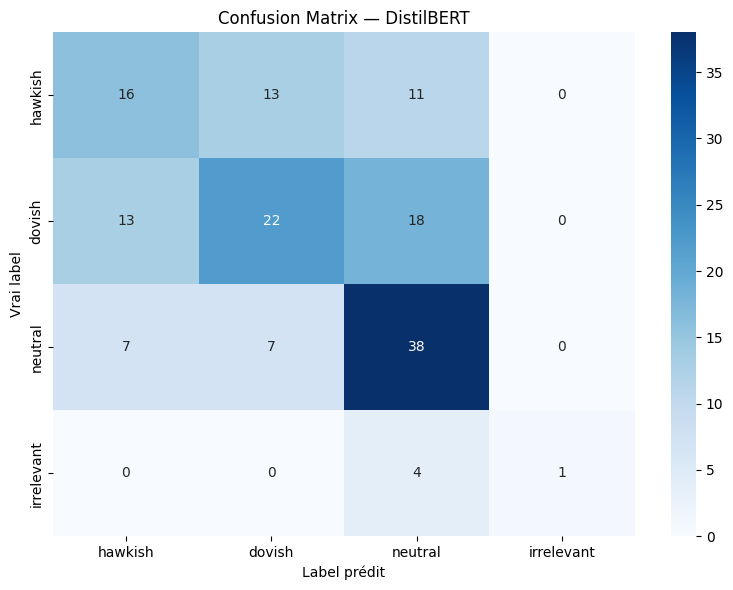

In [50]:
# Matrice de confusion — DistilBERT final

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_bert = confusion_matrix(
    y_true_bert,
    y_pred_bert,
    labels=[0, 1, 2, 3]
)

labels_noms = ["hawkish", "dovish", "neutral", "irrelevant"]

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_noms,
    yticklabels=labels_noms
)

plt.title("Confusion Matrix — DistilBERT")
plt.xlabel("Label prédit")
plt.ylabel("Vrai label")

plt.tight_layout()
plt.show()

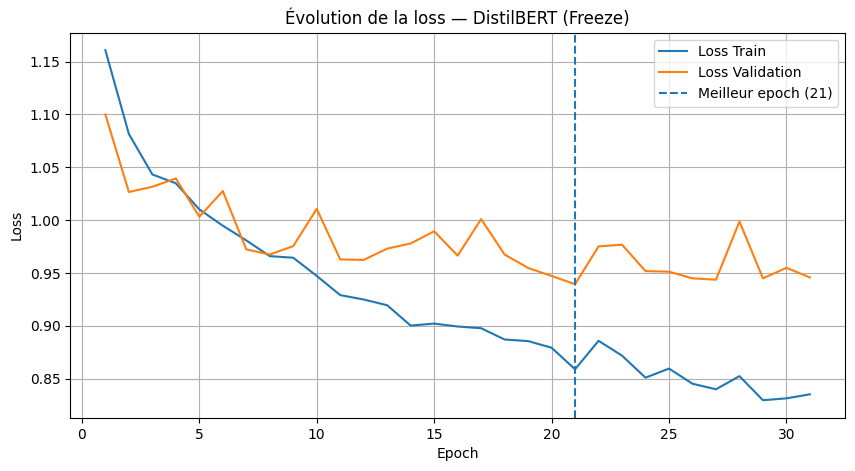

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(train_losses_bert) + 1),
    train_losses_bert,
    label="Loss Train"
)
plt.plot(
    range(1, len(val_losses_bert) + 1),
    val_losses_bert,
    label="Loss Validation"
)
plt.axvline(
    x=best_epoch_bert,
    linestyle="--",
    label=f"Meilleur epoch ({best_epoch_bert})"
)

plt.title("Évolution de la loss — DistilBERT (Freeze)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [67]:
# Baseline : prédire toujours la classe la plus fréquente du train
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train.numpy())
y_pred_base = baseline.predict(np.zeros((len(y_test), 1)))

print(f"Baseline - Accuracy    : {accuracy_score(y_test.numpy(), y_pred_base)*100:.2f}%")
print(f"Baseline - F1 pondéré  : {f1_score(y_test.numpy(), y_pred_base, average='weighted', zero_division=0)*100:.2f}%")

Baseline - Accuracy    : 34.67%
Baseline - F1 pondéré  : 17.85%


In [53]:
# Fine-tuning complet de DistilBERT (toutes les couches sont entraînées)
import copy
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

torch.manual_seed(SEED)

model_ft = DistilBERTClassifier(num_classes=4)
# On dégèle DistilBERT : toutes les couches vont apprendre
for p in model_ft.bert.parameters():
    p.requires_grad = True
model_ft.to(device)

NB_EPOCHS = 5
optimizer_ft = AdamW(model_ft.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = len(train_loader_bert) * NB_EPOCHS
scheduler_ft = get_linear_schedule_with_warmup(
    optimizer_ft,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)
criterion_ft = nn.CrossEntropyLoss()

best_val_loss_ft = float("inf")
best_state_ft = None
best_epoch_ft = 0
train_losses_ft, val_losses_ft = [], []

for epoch in range(NB_EPOCHS):
    # -------- Entraînement --------
    model_ft.train()
    total_loss = 0
    for ids, mask, labels in train_loader_bert:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
        logits = model_ft(input_ids=ids, attention_mask=mask)
        loss = criterion_ft(logits, labels)
        optimizer_ft.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_ft.parameters(), 1.0)
        optimizer_ft.step()
        scheduler_ft.step()
        total_loss += loss.item()
    train_losses_ft.append(total_loss / len(train_loader_bert))

    # -------- Validation --------
    model_ft.eval()
    total_loss = 0
    with torch.no_grad():
        for ids, mask, labels in val_loader_bert:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            total_loss += criterion_ft(model_ft(input_ids=ids, attention_mask=mask), labels).item()
    val_loss = total_loss / len(val_loader_bert)
    val_losses_ft.append(val_loss)

    print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss Train: {train_losses_ft[-1]:.4f} - Loss Val: {val_loss:.4f}")

    # On garde le meilleur modèle selon la validation
    if val_loss < best_val_loss_ft:
        best_val_loss_ft = val_loss
        best_epoch_ft = epoch + 1
        best_state_ft = copy.deepcopy(model_ft.state_dict())

model_ft.load_state_dict(best_state_ft)
print(f"Meilleur modèle : epoch {best_epoch_ft} (Loss Val = {best_val_loss_ft:.4f})")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/5 - Loss Train: 1.1713 - Loss Val: 1.0282
Epoch 2/5 - Loss Train: 0.9694 - Loss Val: 0.9420
Epoch 3/5 - Loss Train: 0.8242 - Loss Val: 0.9308
Epoch 4/5 - Loss Train: 0.6466 - Loss Val: 0.9119
Epoch 5/5 - Loss Train: 0.5611 - Loss Val: 0.9278
Meilleur modèle : epoch 4 (Loss Val = 0.9119)


In [54]:
# Évaluation finale du DistilBERT fine-tuné sur le test set
model_ft.eval()
preds, trues, probs = [], [], []
with torch.no_grad():
    for ids, mask, labels in test_loader_bert:
        ids, mask = ids.to(device), mask.to(device)
        p = torch.softmax(model_ft(input_ids=ids, attention_mask=mask), dim=1)
        probs.extend(p.cpu().numpy())
        preds.extend(p.argmax(dim=1).cpu().numpy())
        trues.extend(labels.cpu().numpy())

y_true_ft, y_pred_ft, y_prob_ft = np.array(trues), np.array(preds), np.array(probs)

print("=== DistilBERT fine-tuné — Test final ===")
print(f"Accuracy    : {accuracy_score(y_true_ft, y_pred_ft)*100:.2f}%")
print(f"F1 pondéré  : {f1_score(y_true_ft, y_pred_ft, average='weighted', zero_division=0)*100:.2f}%")
print(f"F1 macro    : {f1_score(y_true_ft, y_pred_ft, average='macro', zero_division=0)*100:.2f}%")
print(f"AUC pondérée: {roc_auc_score(label_binarize(y_true_ft, classes=[0,1,2,3]), y_prob_ft, average='weighted', multi_class='ovr')*100:.2f}%")

=== DistilBERT fine-tuné — Test final ===
Accuracy    : 54.00%
F1 pondéré  : 52.70%
F1 macro    : 40.49%
AUC pondérée: 73.97%


## 5. Entraînements prolongés du RNN et du LSTM

In [55]:
# Réinitialise le modèle RNN.
model_rnn = RNNClassifier(
    vocab_size=len(mot2idx),
    embed_dim=64,
    hidden_size=128,
    num_classes=4
)

criterion_rnn = nn.CrossEntropyLoss()
optimizer_rnn = torch.optim.Adam(model_rnn.parameters(), lr=0.001)

train_losses_rnn = []
val_losses_rnn  = []

NB_EPOCHS = 100

for epoch in range(NB_EPOCHS):

    # Passe le modèle en mode entraînement.
    model_rnn.train()
    total_loss_train = 0

    for X_batch, y_batch in train_loader:
        predictions = model_rnn(X_batch)
        loss = criterion_rnn(predictions, y_batch)
        optimizer_rnn.zero_grad()
        loss.backward()
        optimizer_rnn.step()
        total_loss_train += loss.item()

    loss_train = total_loss_train / len(train_loader)
    train_losses_rnn.append(loss_train)

    # Suit la perte sur le jeu de validation.
    model_rnn.eval()
    with torch.no_grad():
        predictions_val = model_rnn(X_val)
        loss_val = criterion_rnn(predictions_val, y_val)
        val_losses_rnn.append(loss_val.item())

    # Affiche les pertes toutes les dix époques.
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss Train: {loss_train:.4f} - Loss Val: {loss_val:.4f}")

Epoch 10/100 - Loss Train: 1.0718 - Loss Val: 1.2010
Epoch 20/100 - Loss Train: 0.9978 - Loss Val: 1.2107
Epoch 30/100 - Loss Train: 0.5174 - Loss Val: 2.0647
Epoch 40/100 - Loss Train: 0.2405 - Loss Val: 3.2890
Epoch 50/100 - Loss Train: 0.0794 - Loss Val: 3.6404
Epoch 60/100 - Loss Train: 0.0242 - Loss Val: 4.3449
Epoch 70/100 - Loss Train: 0.0335 - Loss Val: 4.4477
Epoch 80/100 - Loss Train: 0.0170 - Loss Val: 4.5033
Epoch 90/100 - Loss Train: 0.0058 - Loss Val: 4.9749
Epoch 100/100 - Loss Train: 0.0028 - Loss Val: 5.2145


=== Résultats RNN — 100 epochs ===
Accuracy  : 26.00%
Precision : 26.69%
Recall    : 26.00%
F1 Score  : 26.28%
AUC       : 49.54%


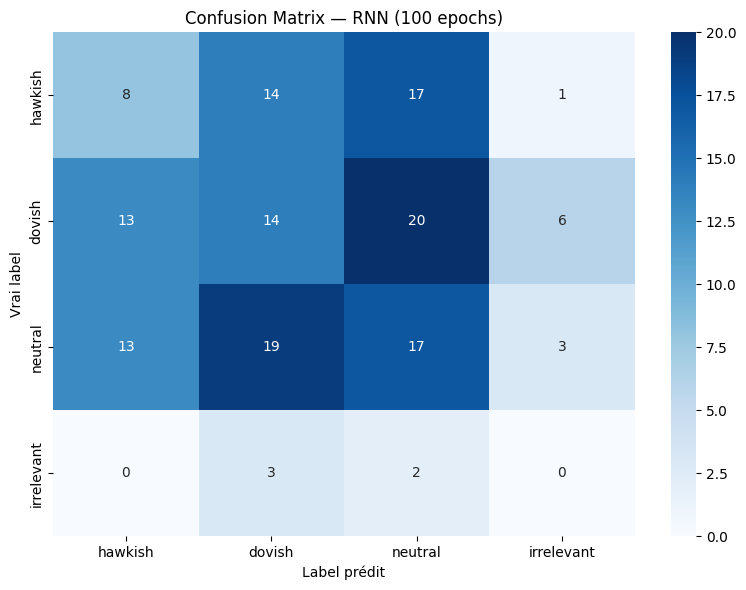

In [56]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize
import numpy as np
import seaborn as sns

# ── Métriques RNN 100 epochs ──
model_rnn.eval()

with torch.no_grad():
    predictions_test = model_rnn(X_test)
    predicted_labels = torch.argmax(predictions_test, dim=1)
    probs = torch.softmax(predictions_test, dim=1).numpy()
    y_true = y_test.numpy()
    y_pred = predicted_labels.numpy()

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall    = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1        = f1_score(y_true, y_pred, average='weighted', zero_division=0)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
auc = roc_auc_score(y_true_bin, probs, average='weighted', multi_class='ovr')

print("=== Résultats RNN — 100 epochs ===")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")
print(f"AUC       : {auc*100:.2f}%")

# ── Confusion Matrix ──
cm = confusion_matrix(y_true, y_pred)
labels_noms = ["hawkish", "dovish", "neutral", "irrelevant"]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_noms, yticklabels=labels_noms)
plt.title("Confusion Matrix — RNN (100 epochs)")
plt.ylabel("Vrai label")
plt.xlabel("Label prédit")
plt.tight_layout()
plt.show()

In [ ]:
# LSTM 100 epochs
model_lstm = LSTMClassifier(
    vocab_size=len(mot2idx),
    embed_dim=64,
    hidden_size=128,
    num_classes=4
)
criterion_lstm = nn.CrossEntropyLoss()
optimizer_lstm = torch.optim.Adam(model_lstm.parameters(), lr=0.001)
train_losses_lstm = []
val_losses_lstm = []
NB_EPOCHS = 100

for epoch in range(NB_EPOCHS):
    model_lstm.train()
    total_loss_train = 0
    for X_batch, y_batch in train_loader:
        predictions = model_lstm(X_batch)
        loss = criterion_lstm(predictions, y_batch)
        optimizer_lstm.zero_grad()
        loss.backward()
        optimizer_lstm.step()
        total_loss_train += loss.item()
    loss_train = total_loss_train / len(train_loader)
    train_losses_lstm.append(loss_train)
    model_lstm.eval()
    with torch.no_grad():
        predictions_val = model_lstm(X_val)
        loss_val = criterion_lstm(predictions_val, y_val)
        val_losses_lstm.append(loss_val.item())
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{NB_EPOCHS} - Loss Train: {loss_train:.4f} - Loss Val: {loss_val:.4f}")

Epoch 10/100 - Loss Train: 1.1122 - Loss Val: 1.1570
Epoch 20/100 - Loss Train: 0.7877 - Loss Val: 1.5308
Epoch 30/100 - Loss Train: 0.2888 - Loss Val: 2.4284
Epoch 40/100 - Loss Train: 0.1635 - Loss Val: 2.8656
Epoch 50/100 - Loss Train: 0.0988 - Loss Val: 3.3809
Epoch 60/100 - Loss Train: 0.0865 - Loss Val: 3.4087
Epoch 70/100 - Loss Train: 0.0501 - Loss Val: 3.8394
Epoch 80/100 - Loss Train: 0.0585 - Loss Val: 4.0170
Epoch 90/100 - Loss Train: 0.0382 - Loss Val: 4.3567


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import label_binarize
import seaborn as sns

model_lstm.eval()
with torch.no_grad():
    predictions_test = model_lstm(X_test)
    predicted_labels = torch.argmax(predictions_test, dim=1)
    probs = torch.softmax(predictions_test, dim=1).numpy()
    y_true = y_test.numpy()
    y_pred = predicted_labels.numpy()

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall    = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1        = f1_score(y_true, y_pred, average='weighted', zero_division=0)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
auc = roc_auc_score(y_true_bin, probs, average='weighted', multi_class='ovr')

print("=== Résultats LSTM — 100 epochs ===")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")
print(f"AUC       : {auc*100:.2f}%")

cm = confusion_matrix(y_true, y_pred)
labels_noms = ["hawkish", "dovish", "neutral", "irrelevant"]
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels_noms, yticklabels=labels_noms)
plt.title("Confusion Matrix — LSTM (100 epochs)")
plt.ylabel("Vrai label")
plt.xlabel("Label prédit")
plt.tight_layout()
plt.show()

## 6. Architectures récurrentes améliorées

In [ ]:
# ─────────────────────────────────────────────────────────
# Architectures améliorées RNN et LSTM
#
# Améliorations :
# 1. Dropout → réduit le risque de surapprentissage
# 2. Weight decay → sera appliqué lors de l'entraînement
#    pour régulariser les paramètres du modèle
# ─────────────────────────────────────────────────────────

class RNNClassifierImproved(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_classes, dropout=0.3):
        super(RNNClassifierImproved, self).__init__()

        # Couche Embedding : convertit les indices des mots en vecteurs
        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        # Dropout pour limiter le surapprentissage
        self.dropout = nn.Dropout(dropout)

        # Couche RNN
        self.rnn = nn.RNN(
            embed_dim,
            hidden_size,
            batch_first=True
        )

        # Couche de classification
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))

        output, hidden = self.rnn(embedded)

        out = self.fc(self.dropout(hidden[-1]))

        return out


class LSTMClassifierImproved(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_classes, dropout=0.3):
        super(LSTMClassifierImproved, self).__init__()

        # Couche Embedding
        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        # Dropout pour limiter le surapprentissage
        self.dropout = nn.Dropout(dropout)

        # Couche LSTM
        self.lstm = nn.LSTM(
            embed_dim,
            hidden_size,
            batch_first=True
        )

        # Couche de classification
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))

        output, (hidden, cell) = self.lstm(embedded)

        out = self.fc(self.dropout(hidden[-1]))

        return out

### Entraînement avec pondération des classes et arrêt anticipé

In [ ]:
# Améliorations : Class Weights + Early Stopping
# Important : l'Early Stopping utilise la validation, jamais le test.

import numpy as np
import copy
from torch.nn import CrossEntropyLoss

# Poids relatifs aux fréquences des classes du train set.
label_counts = torch.tensor([157, 237, 289, 17], dtype=torch.float)
class_weights = 1.0 / label_counts
class_weights = class_weights / class_weights.sum()

print("Poids par classe :")
print(f"  hawkish    : {class_weights[0]:.4f}")
print(f"  dovish     : {class_weights[1]:.4f}")
print(f"  neutral    : {class_weights[2]:.4f}")
print(f"  irrelevant : {class_weights[3]:.4f}")

criterion_weighted = CrossEntropyLoss(weight=class_weights)

model_rnn_best = RNNClassifierImproved(
    vocab_size=len(mot2idx),
    embed_dim=64,
    hidden_size=128,
    num_classes=4,
    dropout=0.3
)

optimizer_rnn_best = torch.optim.Adam(
    model_rnn_best.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

patience = 10
best_val_loss = float("inf")
epochs_no_improve = 0
best_epoch_rnn = 0
best_model_state = None

train_losses_best = []
val_losses_best = []

NB_EPOCHS = 100

for epoch in range(NB_EPOCHS):

    model_rnn_best.train()
    total_loss_train = 0

    for X_batch, y_batch in train_loader:
        predictions = model_rnn_best(X_batch)
        loss = criterion_weighted(predictions, y_batch)

        optimizer_rnn_best.zero_grad()
        loss.backward()
        optimizer_rnn_best.step()

        total_loss_train += loss.item()

    loss_train = total_loss_train / len(train_loader)
    train_losses_best.append(loss_train)

    # Validation
    model_rnn_best.eval()
    with torch.no_grad():
        predictions_val = model_rnn_best(X_val)
        loss_val = criterion_weighted(predictions_val, y_val)

    val_losses_best.append(loss_val.item())

    # Early stopping basé sur la validation
    if loss_val.item() < best_val_loss:
        best_val_loss = loss_val.item()
        best_epoch_rnn = epoch + 1
        epochs_no_improve = 0
        best_model_state = copy.deepcopy(model_rnn_best.state_dict())
    else:
        epochs_no_improve += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{NB_EPOCHS} - "
            f"Loss Train: {loss_train:.4f} - "
            f"Loss Val: {loss_val.item():.4f}"
        )

    if epochs_no_improve >= patience:
        print(f"\nEarly Stopping à l'epoch {epoch+1}.")
        print(
            f"Meilleur modèle : epoch {best_epoch_rnn} "
            f"(Loss Val = {best_val_loss:.4f})"
        )
        break

model_rnn_best.load_state_dict(best_model_state)
print(f"\nMeilleur epoch RNN : {best_epoch_rnn}")


In [ ]:
# Évaluation finale du RNN amélioré sur le test set
# Le test set n'intervient pas dans l'Early Stopping.

model_rnn_best.eval()

with torch.no_grad():
    predictions_test = model_rnn_best(X_test)
    predicted_labels = torch.argmax(predictions_test, dim=1)
    probs = torch.softmax(predictions_test, dim=1).numpy()

y_true = y_test.numpy()
y_pred = predicted_labels.numpy()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
auc = roc_auc_score(
    y_true_bin,
    probs,
    average="weighted",
    multi_class="ovr"
)

print("=== Résultats RNN — Early Stopping + Class Weights ===")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")
print(f"AUC       : {auc*100:.2f}%")

cm = confusion_matrix(y_true, y_pred)
labels_noms = ["hawkish", "dovish", "neutral", "irrelevant"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=labels_noms,
    yticklabels=labels_noms
)
plt.title("Confusion Matrix — RNN amélioré")
plt.ylabel("Vrai label")
plt.xlabel("Label prédit")
plt.tight_layout()
plt.show()


In [ ]:
# LSTM amélioré :
# Dropout + Weight Decay + Class Weights + Early Stopping
# L'Early Stopping est basé uniquement sur la validation.

model_lstm_best = LSTMClassifierImproved(
    vocab_size=len(mot2idx),
    embed_dim=64,
    hidden_size=128,
    num_classes=4,
    dropout=0.3
)

optimizer_lstm_best = torch.optim.Adam(
    model_lstm_best.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

patience = 10
best_val_loss_lstm = float("inf")
epochs_no_improve = 0
best_epoch_lstm = 0
best_model_state_lstm = None

train_losses_lstm_best = []
val_losses_lstm_best = []

NB_EPOCHS = 100

for epoch in range(NB_EPOCHS):

    model_lstm_best.train()
    total_loss_train = 0

    for X_batch, y_batch in train_loader:
        predictions = model_lstm_best(X_batch)
        loss = criterion_weighted(predictions, y_batch)

        optimizer_lstm_best.zero_grad()
        loss.backward()
        optimizer_lstm_best.step()

        total_loss_train += loss.item()

    loss_train = total_loss_train / len(train_loader)
    train_losses_lstm_best.append(loss_train)

    # Validation
    model_lstm_best.eval()
    with torch.no_grad():
        predictions_val = model_lstm_best(X_val)
        loss_val = criterion_weighted(predictions_val, y_val)

    val_losses_lstm_best.append(loss_val.item())

    # Arrêt anticipé fondé sur la validation.
    if loss_val.item() < best_val_loss_lstm:
        best_val_loss_lstm = loss_val.item()
        best_epoch_lstm = epoch + 1
        epochs_no_improve = 0
        best_model_state_lstm = copy.deepcopy(model_lstm_best.state_dict())
    else:
        epochs_no_improve += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{NB_EPOCHS} - "
            f"Loss Train: {loss_train:.4f} - "
            f"Loss Val: {loss_val.item():.4f}"
        )

    if epochs_no_improve >= patience:
        print(f"\nEarly Stopping à l'epoch {epoch+1}.")
        print(
            f"Meilleur modèle : epoch {best_epoch_lstm} "
            f"(Loss Val = {best_val_loss_lstm:.4f})"
        )
        break

model_lstm_best.load_state_dict(best_model_state_lstm)
print(f"\nMeilleur epoch LSTM : {best_epoch_lstm}")


In [ ]:
# Évaluation finale du LSTM amélioré sur le test set
model_lstm_best.eval()

with torch.no_grad():
    predictions_test = model_lstm_best(X_test)
    predicted_labels = torch.argmax(predictions_test, dim=1)
    probs = torch.softmax(predictions_test, dim=1).numpy()

y_true = y_test.numpy()
y_pred = predicted_labels.numpy()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
auc = roc_auc_score(
    y_true_bin,
    probs,
    average="weighted",
    multi_class="ovr"
)

print("=== Résultats LSTM — Early Stopping + Class Weights ===")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")
print(f"AUC       : {auc*100:.2f}%")

cm = confusion_matrix(y_true, y_pred)
labels_noms = ["hawkish", "dovish", "neutral", "irrelevant"]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=labels_noms,
    yticklabels=labels_noms
)
plt.title("Confusion Matrix — LSTM amélioré")
plt.ylabel("Vrai label")
plt.xlabel("Label prédit")
plt.tight_layout()
plt.show()


## 7. Démonstration interactive

In [ ]:
import gradio as gr
import torch
import torch.nn as nn


# ═════════════════════════════════════════════════════════════
# MAPPING DES LABELS
# ═════════════════════════════════════════════════════════════

idx2label = {
    0: "🦅 Hawkish",
    1: "🕊️ Dovish",
    2: "⚖️ Neutral",
    3: "🚫 Irrelevant"
}


# ═════════════════════════════════════════════════════════════
# FONCTION DE PRÉDICTION
# ═════════════════════════════════════════════════════════════

def predire_stance(phrase):

    # ── RNN ─────────────────────────────────────────────
    model_rnn_best.eval()

    nombres = phrase_vers_nombres(phrase)
    x = torch.tensor([nombres], dtype=torch.long)

    with torch.no_grad():
        logits_rnn = model_rnn_best(x)
        probs_rnn = torch.softmax(logits_rnn, dim=1)[0]
        pred_rnn = torch.argmax(probs_rnn).item()


    # ── LSTM ────────────────────────────────────────────
    model_lstm_best.eval()

    with torch.no_grad():
        logits_lstm = model_lstm_best(x)
        probs_lstm = torch.softmax(logits_lstm, dim=1)[0]
        pred_lstm = torch.argmax(probs_lstm).item()


    # ── DistilBERT ──────────────────────────────────────
    model_bert.eval()

    tokens = tokenizer(
        phrase,
        return_tensors="pt",
        truncation=True,
        max_length=128,
        padding=True
    )

    input_ids = tokens["input_ids"].to(device)
    attention_mask = tokens["attention_mask"].to(device)

    with torch.no_grad():
        logits_bert = model_bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probs_bert = torch.softmax(logits_bert, dim=1)[0].cpu()
        pred_bert = torch.argmax(probs_bert).item()


    # ── Résultats ───────────────────────────────────────

    resultat_rnn = (
        f"{idx2label[pred_rnn]}  —  "
        f"{probs_rnn[pred_rnn].item() * 100:.1f}%"
    )

    resultat_lstm = (
        f"{idx2label[pred_lstm]}  —  "
        f"{probs_lstm[pred_lstm].item() * 100:.1f}%"
    )

    resultat_bert = (
        f"{idx2label[pred_bert]}  —  "
        f"{probs_bert[pred_bert].item() * 100:.1f}%"
    )

    return resultat_rnn, resultat_lstm, resultat_bert


# ═════════════════════════════════════════════════════════════
# DESIGN DE L'INTERFACE
# ═════════════════════════════════════════════════════════════

css = """

.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
}


/* ── En-tête ─────────────────────────────────────────── */

.hero {
    text-align: center;
    padding: 25px 10px 20px 10px;
}

.hero h1 {
    font-size: 40px;
    margin-bottom: 8px;
    font-weight: 700;
}

.hero p {
    font-size: 17px;
    color: #666;
    margin-top: 0;
}


/* ── Zone de saisie ──────────────────────────────────── */

.input-card {
    border: 1px solid #e5e5e5 !important;
    border-radius: 18px !important;
    padding: 20px !important;
    box-shadow: 0 4px 15px rgba(0,0,0,0.05);
}


/* ── Bouton principal ────────────────────────────────── */

#predict-btn {
    background: #F5B800 !important;
    color: #111111 !important;
    border: none !important;
    font-weight: 700 !important;
}

#predict-btn:hover {
    background: #DCA600 !important;
}


/* ── Cartes résultats ────────────────────────────────── */

.model-card {
    border: 1px solid #e4e4e4 !important;
    border-radius: 16px !important;
    padding: 15px !important;
    box-shadow: 0 3px 12px rgba(0,0,0,0.05);
    min-height: 170px;
}

.model-card h3 {
    text-align: center;
    margin-bottom: 5px;
}

.model-card p {
    text-align: center;
    color: #777;
    font-size: 13px;
}


/* ── Footer ──────────────────────────────────────────── */

.footer {
    text-align: center;
    margin-top: 30px;
    padding: 15px;
    color: #888;
    font-size: 13px;
}

"""


# ═════════════════════════════════════════════════════════════
# CONSTRUCTION DE L'INTERFACE
# ═════════════════════════════════════════════════════════════

with gr.Blocks(
    title="BCE Stance Classifier"
) as interface:


    # ── En-tête ─────────────────────────────────────────

    gr.HTML("""
    <div class="hero">

        <h1>🏦 BCE Stance Classifier</h1>

        <p>
            Analyse automatique de la position monétaire
            à partir des minutes de la Banque Centrale Européenne
        </p>

    </div>
    """)


    # ── Zone de saisie ──────────────────────────────────

    with gr.Group(elem_classes="input-card"):

        phrase_input = gr.Textbox(
            label="Phrase à analyser",
            placeholder=(
                "Ex : The interest rates should be raised "
                "to control inflation..."
            ),
            lines=3
        )

        with gr.Row():

            clear_btn = gr.Button(
                "Effacer"
            )

            predict_btn = gr.Button(
                "Analyser la phrase",
                variant="primary",
                elem_id="predict-btn"
            )


    # ── Titre résultats ─────────────────────────────────

    gr.Markdown(
        """
        ## Résultats de la classification

        Comparaison des prédictions obtenues par les trois modèles.
        """
    )


    # ── Résultats des trois modèles ─────────────────────

    with gr.Row():

        # RNN
        with gr.Column(elem_classes="model-card"):

            gr.HTML("""
            <h3>RNN</h3>
            <p>Réseau neuronal récurrent</p>
            """)

            output_rnn = gr.Textbox(
                label="Prédiction",
                interactive=False
            )


        # LSTM
        with gr.Column(elem_classes="model-card"):

            gr.HTML("""
            <h3>LSTM</h3>
            <p>Long Short-Term Memory</p>
            """)

            output_lstm = gr.Textbox(
                label="Prédiction",
                interactive=False
            )


        # DistilBERT
        with gr.Column(elem_classes="model-card"):

            gr.HTML("""
            <h3>DistilBERT</h3>
            <p>Transfer Learning</p>
            """)

            output_bert = gr.Textbox(
                label="Prédiction",
                interactive=False
            )


    # ── Exemples ────────────────────────────────────────

    gr.Markdown("## Exemples de phrases")

    gr.Examples(

        examples=[

            [
                "The interest rates should be raised "
                "to control inflation."
            ],

            [
                "The economy needs stimulus "
                "to recover from the slowdown."
            ],

            [
                "The meeting will take place "
                "next month in Frankfurt."
            ],

            [
                "The monetary policy stance "
                "remains broadly balanced."
            ]

        ],

        inputs=phrase_input,

        label="Cliquez sur un exemple pour le tester"
    )


    # ── Footer ──────────────────────────────────────────

    gr.HTML("""
    <div class="footer">

        <b>Projet de classification NLP</b><br>

        RNN &nbsp;•&nbsp;
        LSTM &nbsp;•&nbsp;
        DistilBERT

    </div>
    """)


    # ═════════════════════════════════════════════════════
    # ACTIONS
    # ═════════════════════════════════════════════════════

    predict_btn.click(

        fn=predire_stance,

        inputs=phrase_input,

        outputs=[
            output_rnn,
            output_lstm,
            output_bert
        ]
    )


    clear_btn.click(

        fn=lambda: ("", "", "", ""),

        inputs=[],

        outputs=[
            phrase_input,
            output_rnn,
            output_lstm,
            output_bert
        ]
    )


# ═════════════════════════════════════════════════════════════
# LANCEMENT
# ═════════════════════════════════════════════════════════════

interface.launch(share=False, css=css)

## Courbes d’entraînement et de validation

In [ ]:
# Graphiques des modèles améliorés
# Les courbes montrent Train vs Validation.
# Le test set est réservé à l'évaluation finale.

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# RNN
axes[0].plot(
    range(1, len(train_losses_best) + 1),
    train_losses_best,
    label="Loss Train"
)
axes[0].plot(
    range(1, len(val_losses_best) + 1),
    val_losses_best,
    label="Loss Validation"
)
axes[0].axvline(
    x=best_epoch_rnn,
    linestyle="--",
    label=f"Meilleur epoch ({best_epoch_rnn})"
)
axes[0].set_title("RNN — Early Stopping + Class Weights")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# LSTM
axes[1].plot(
    range(1, len(train_losses_lstm_best) + 1),
    train_losses_lstm_best,
    label="Loss Train"
)
axes[1].plot(
    range(1, len(val_losses_lstm_best) + 1),
    val_losses_lstm_best,
    label="Loss Validation"
)
axes[1].axvline(
    x=best_epoch_lstm,
    linestyle="--",
    label=f"Meilleur epoch ({best_epoch_lstm})"
)
axes[1].set_title("LSTM — Early Stopping + Class Weights")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 8. Résultats, discussion et conclusion

# Comparaison des résultats actuels

Les métriques ci-dessous proviennent des sorties de cette exécution : cellules 71 (RNN amélioré), 73 (LSTM amélioré) et 58 (DistilBERT gelé).

| Modèle | Accuracy | Precision | Recall | F1-score pondéré | AUC pondérée |
|--------|----------|-----------|--------|------------------|--------------|
| RNN amélioré | 26.67% | 41.70% | 26.67% | 15.52% | 47.85% |
| LSTM amélioré | 34.67% | 37.65% | 34.67% | 24.68% | 53.09% |
| **DistilBERT (Freeze)** | **52.67%** | **50.79%** | **52.67%** | **51.04%** | **71.31%** |

## Observations

- DistilBERT obtient les meilleurs résultats pour les cinq métriques du tableau.
- Parmi les modèles récurrents, le LSTM dépasse le RNN en accuracy, recall, F1-score et AUC ; le RNN a une precision supérieure à celle du LSTM.
- Le RNN amélioré a une accuracy de 26.67% et un F1-score pondéré de 15.52%. Le LSTM amélioré obtient une accuracy de 34.67% et un F1-score pondéré de 24.68%.
- Le jeu de données est déséquilibré, en particulier pour la classe irrelevant. Ces résultats doivent être interprétés en tenant compte de cette distribution.
- Pour DistilBERT, les paramètres préentraînés restent gelés et seule la couche de classification est entraînée.

### Note historique — rapport de stage

Les métriques du rapport, obtenues avant le tri reproductible du vocabulaire, sont conservées ici uniquement à titre de référence historique ; elles ne représentent pas cette exécution.

| Modèle | Accuracy | Precision | Recall | F1-score pondéré | AUC pondérée |
|--------|----------|-----------|--------|------------------|--------------|
| RNN amélioré | 34.67% | 38.60% | 34.67% | 21.32% | 48.55% |
| LSTM amélioré | 33.33% | 33.35% | 33.33% | 25.88% | 50.22% |
| DistilBERT (Freeze) | 49.33% | 50.83% | 49.33% | 48.00% | 72.53% |

## Discussion : limiter le surapprentissage

### Constat

Les expérimentations prolongées montrent un écart entre les pertes d’entraînement et de validation, particulièrement pour les modèles RNN et LSTM. La hausse de la perte de validation pendant les entraînements prolongés est compatible avec un surapprentissage.

### Déséquilibre des classes

Le jeu d’entraînement contient les effectifs suivants :

- neutral : 289 exemples (41 %)
- dovish : 237 exemples (34 %)
- hawkish : 157 exemples (22 %)
- irrelevant : 17 exemples (3 %)

La classe irrelevant est fortement sous-représentée. Des pondérations de classes ont été utilisées pour donner davantage de poids aux erreurs sur les classes minoritaires.

### Dropout

Un taux de Dropout de 0.3 est utilisé dans les architectures améliorées du RNN et du LSTM. Le Dropout désactive aléatoirement certains neurones pendant l’entraînement afin de limiter la dépendance du modèle à certaines caractéristiques.

### Arrêt anticipé

L’arrêt anticipé sélectionne le meilleur modèle à partir de la perte de validation. Les sorties de cette exécution indiquent :

- RNN : meilleure époque = 2, arrêt à l’époque 12.
- LSTM : meilleure époque = 8, arrêt à l’époque 18.
- DistilBERT : meilleure époque = 21, arrêt à l’époque 31.

Le meilleur état des poids est restauré après l’entraînement.

### Régularisation et transfert d’apprentissage

Un weight decay de 1e-4 est appliqué avec l’optimiseur Adam du RNN et du LSTM afin de pénaliser les poids de grande amplitude.

DistilBERT (distilbert-base-uncased) est utilisé comme extracteur de caractéristiques : ses paramètres sont gelés et seule sa couche de classification est entraînée.

La comparaison des métriques actuelles est présentée dans le tableau de la section précédente. Les valeurs historiques du rapport y sont séparées et ne sont pas utilisées pour décrire cette exécution.

# Conclusion

Le notebook a été réexécuté avec un vocabulaire trié de manière reproductible. Sur le jeu de test, DistilBERT obtient les meilleurs résultats actuels : accuracy 52.67%, precision pondérée 50.79%, recall 52.67%, F1-score pondéré 51.04% et AUC pondérée 71.31%.

Parmi les modèles récurrents, le LSTM obtient une accuracy de 34.67%, un F1-score pondéré de 24.68% et une AUC pondérée de 53.09%. Le RNN obtient respectivement 26.67%, 15.52% et 47.85%. Le RNN a toutefois une precision pondérée supérieure à celle du LSTM : 41.70% contre 37.65%.

Le jeu de données comprend :

- 700 exemples d’entraînement ;
- 150 exemples de validation ;
- 150 exemples de test.

La classe irrelevant reste minoritaire dans le jeu d’entraînement : 17 exemples sur 700. Les métriques historiques du rapport sont présentées séparément dans la section de comparaison et ne doivent pas être confondues avec les résultats actuels.